# Heat Equation, Explicit

## Problem
$$
u_t = u_{xx}, \quad 0<x<1, \quad 0<t\le 0.5, \quad u(x,0)=\sin(\pi x), \quad u(0,t)=u(1,t)=0
$$
Exact solution $u = e^{-\pi^2 t}\sin(\pi x)$.

## Discretization
Forward in time, centered in space

$$
u_i^{n+1} = u_i^n + r\left(u_{i-1}^n - 2u_i^n + u_{i+1}^n\right), \quad r = \frac{\Delta t}{h^2}
$$

Stable for $r \le 1/2$. For the instability demo the initial condition is the hat $\min(2x, 2-2x)$, since a pure sine has almost no high-frequency content.

## Code

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from heat import ftcs, hat

In [2]:
T_END = 0.5
N = 20
h = 1/N
x = np.linspace(0, 1, N+1)
ex = lambda t: np.exp(-np.pi**2*t)*np.sin(np.pi*x)

In [3]:
r = 0.4
nt = int(round(T_END/(r*h**2)))
u, hist = ftcs(np.sin(np.pi*x), r, nt)
np.max(np.abs(u-ex(nt*r*h**2)))

np.float64(0.00010192992530231714)

In [4]:
r2 = 0.6
nt2 = int(round(T_END/(r2*h**2)))
u2, hist2 = ftcs(hat(x), r2, nt2)
hist_s = ftcs(hat(x), r, nt)[1]
np.max(np.abs(u2))

np.float64(6.730136761663325e+44)

### Snapshots

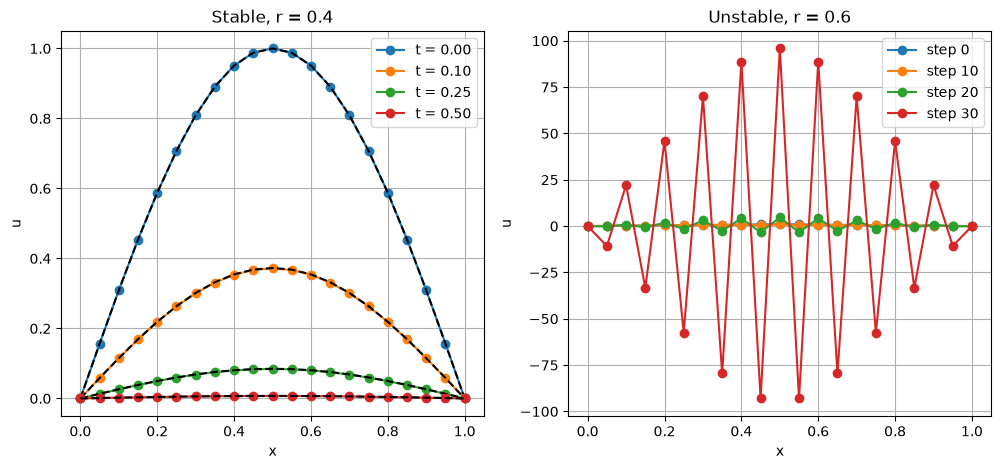

In [5]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
for k in [0, nt//5, nt//2, nt]:
    t = k*r*h**2
    plt.plot(x, hist[k], 'o-', label=f"t = {t:.2f}")
    plt.plot(x, ex(t), 'k--')
plt.xlabel("x")
plt.ylabel("u")
plt.title("Stable, r = 0.4")
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
for k in [0, 10, 20, 30]:
    plt.plot(x, hist2[k], 'o-', label=f"step {k}")
plt.xlabel("x")
plt.ylabel("u")
plt.title("Unstable, r = 0.6")
plt.legend()
plt.grid(True)
plt.savefig("../figures/07_snapshots.png", dpi=300, bbox_inches="tight")
plt.show()

### Growth

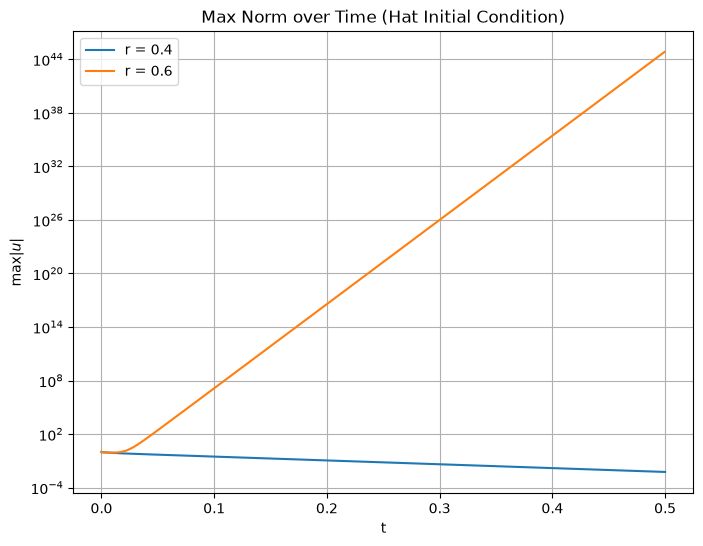

In [6]:
plt.figure(figsize=(8, 6))
plt.semilogy(np.arange(nt+1)*r*h**2, np.max(np.abs(hist_s), axis=1), label="r = 0.4")
plt.semilogy(np.arange(nt2+1)*r2*h**2, np.max(np.abs(hist2), axis=1), label="r = 0.6")
plt.xlabel("t")
plt.ylabel(r"$\max |u|$")
plt.title("Max Norm over Time (Hat Initial Condition)")
plt.legend()
plt.grid(True)
plt.savefig("../figures/07_growth.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusion
At r = 0.4 the solution follows $e^{-\pi^2 t}\sin(\pi x)$ with a max error of 1e-4. At r = 0.6 the hat data blows up to above 1e44 by t = 0.5.